In [2]:
import arcpy
import os
from pathlib import Path

In [3]:
cwd = Path(os.getcwd())
arcpy.env.workspace = cwd
arcpy.env.overwriteOutput = True
pennsylvaniaCountiesFolder = cwd/"Pennsylvania_Counties"
pennsylvaniaCounties = pennsylvaniaCountiesFolder/"PaCounty2025_07.shp"

paLandCoverFolder = cwd/"PA_Land_Cover"
paLandCoverPath = paLandCoverFolder/"PA_Land_Cover.tif"
paLandCover = arcpy.sa.Raster("PA_Land_Cover/PA_Land_Cover.tif")

# Question 2

Part 1: selecting Philadelphia County

In [4]:
paCountiesDescribe = arcpy.Describe(pennsylvaniaCounties)

"""County names seem to be in COUNTY_NAM. Going to make a list of values that the field holds"""
paCountiesSearchCursor = arcpy.da.SearchCursor(pennsylvaniaCounties, ["COUNTY_NAM"])
paCountyNames = [row[0] for row in paCountiesSearchCursor]
paCountyNames.sort()

"""From this list, we can see that Philadelphia county has the name of 'PHILADELPHIA'. I will now select this county"""
philadelphiaSelect = arcpy.management.SelectLayerByAttribute(pennsylvaniaCounties, "", "COUNTY_NAM = 'PHILADELPHIA'")
arcpy.management.CopyFeatures(philadelphiaSelect, pennsylvaniaCountiesFolder/"PhiladelphiaCounty.shp")

<Result 'C:\\Users\\brian\\Documents\\2026-2027\\Fall 2026\\Spatial Programming\\Week 11\\Pennsylvania_Counties\\PhiladelphiaCounty.shp'>

Part 2: clipping Pennsylvania land cover data down to just Philadelphia county

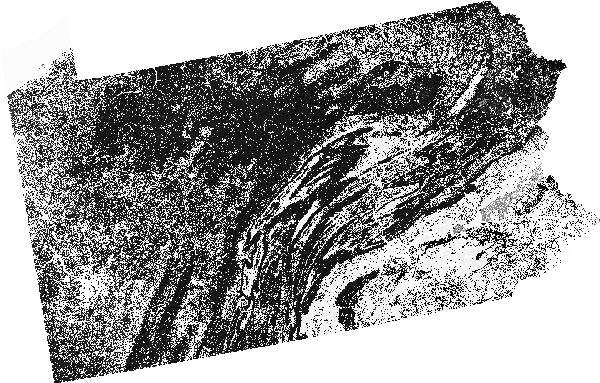

In [5]:
philadelphiaCounty = pennsylvaniaCountiesFolder/"PhiladelphiaCounty.shp"
paLandCover

I had an error trying to clip this so I used ExtractByMask() instead. Running ExtractByMask() automatically saves an output raster for some reason. The resulting raster is called "Extract_PA_Land1.tif"

In [6]:
philadelphiaLandCover = arcpy.sa.ExtractByMask(paLandCover, philadelphiaCounty)

Part 3: reclassifying land cover values

In [7]:
woodlandValues = [38, 64, 103, 133, 134, 231, 232, 236]
woodlandRemapList = [[value, 1] for value in woodlandValues]

shrublandValues = [403, 450]
shrublandRemapList = [[value, 2] for value in shrublandValues]

vegetationValues = [552, 553, 556, 557, 558, 561, 563]
vegetationRemapList = [[value, 3] for value in vegetationValues]

urbanValues = [567, 568, 574, 575, 580, 581, 582, 583, 584]
urbanRemapList = [[value, 4] for value in urbanValues]

remapList = woodlandRemapList + shrublandRemapList + vegetationRemapList + urbanRemapList + [[579, 5]]

philadelphiaLandCoverRemap = arcpy.sa.RemapValue(remapList)
philadelphiaLandCoverReclassify = arcpy.sa.Reclassify(philadelphiaLandCover, "Value", philadelphiaLandCoverRemap)
philadelphiaLandCoverReclassify.save("PhiladelphiaLandCoverReclassified.tif")

# Question 3

Part 1: converting the reclassified land cover raster to polygons

In [8]:
arcpy.conversion.RasterToPolygon(philadelphiaLandCoverReclassify, "PhiladelphiaCountyLandCover.shp", "NO_SIMPLIFY")

<Result 'C:\\Users\\brian\\Documents\\2026-2027\\Fall 2026\\Spatial Programming\\Week 11\\PhiladelphiaCountyLandCover.shp'>

Part 2: adding land cover type as a text field to the shapefile of Philadelphia County land cover

In [9]:
philadelphiaLandCoverPolygon = "PhiladelphiaCountyLandCover.shp"
arcpy.management.AddField(philadelphiaLandCoverPolygon, "LandType", "TEXT")

<Result 'PhiladelphiaCountyLandCover.shp'>

Part 3: assigning values to the "LandType" field

In [10]:
gridcodeValues = []
with arcpy.da.SearchCursor(philadelphiaLandCoverPolygon, ["gridcode"]) as c:
    for row in c:
        gridcodeValues.append(row[0])
gridcodeValues = set(gridcodeValues)
gridcodeValues

{1, 2, 3, 4, 5, 246}

So the "gridcode" field is the value of the raster before it was converted to a polygon

In [11]:
landCoverTypes = {1: "Woodland", 2: "Shrubland", 3: "Vegetation", 4: "Urban", 5: "Water"}
with arcpy.da.UpdateCursor(philadelphiaLandCoverPolygon, ["gridcode", "LandType"], "gridcode < 6") as c:
    for row in c:
        row[1] = landCoverTypes[row[0]]
        c.updateRow(row)

# Question 4

Part 1: dissolving the different polygons

In [13]:
arcpy.management.Dissolve(philadelphiaLandCoverPolygon, "PhiladelphiaCountyLandCover_Dissolve.shp", "LandType")

<Result 'C:\\Users\\brian\\Documents\\2026-2027\\Fall 2026\\Spatial Programming\\Week 11\\PhiladelphiaCountyLandCover_Dissolve.shp'>

Part 2: Calculating total area

In [24]:
philadelphiaLandCoverDissolved = "PhiladelphiaCountyLandCover_Dissolve.shp"

# Calculating area of each feature
# arcpy.management.CalculateGeometryAttributes(philadelphiaLandCoverDissolved, [["areaKm2", "AREA"]], "KILOMETERS", "SQUARE_KILOMETERS")
# arcpy.Describe(philadelphiaLandCoverDissolved)
landCoverCategories = []
landCoverArea = []
with arcpy.da.SearchCursor(philadelphiaLandCoverDissolved, ["LandType", "SHAPE@AREA"]) as c:
    for row in c:
        landCoverCategories.append(row[0])
        landCoverArea.append(row[1])
totalArea = sum(landCoverArea)
print("The total area of the 5 land cover types in Philadelphia County is {:.2f}".format(totalArea))

The total area of the 5 land cover types in Philadelphia County is 368454600.00


In [27]:
for i in range(len(landCoverCategories)):
    landCover = landCoverCategories[i]
    area = landCoverArea[i]
    areaProportion = 100 * area/totalArea
    print("The land cover type {0} takes up {1:.2f}% of the land in Philadelphia County".format(landCover, areaProportion))

The land cover type   takes up 0.10% of the land in Philadelphia County
The land cover type Shrubland takes up 0.33% of the land in Philadelphia County
The land cover type Urban takes up 86.09% of the land in Philadelphia County
The land cover type Vegetation takes up 0.86% of the land in Philadelphia County
The land cover type Water takes up 4.79% of the land in Philadelphia County
The land cover type Woodland takes up 7.83% of the land in Philadelphia County
